In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
columns = ['var','skewness','curtosis','entropy','class']
df = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt", index_col=False, names=columns)

In [ ]:
df.head()

In [ ]:
f, ax = plt.subplots(1, 4, figsize=(10,3))
vis1 = sns.distplot(df["var"], bins=10, ax = ax[0])
vis2 = sns.distplot(df["skewness"], bins=10, ax = ax[1])
vis3 = sns.distplot(df["curtosis"], bins=10, ax = ax[2])
vis4 = sns.distplot(df["entropy"], bins=10, ax = ax[3])
#f.savefig('subplot.png')

In [ ]:
sns.pairplot(df, hue='class')

In [6]:
X = df.iloc[:,0:4].values
y =df.iloc[:,4].values

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

In [8]:
from sklearn.preprocessing import StandardScaler
X_train_sd = StandardScaler().fit_transform(X_train)
X_test_sd = StandardScaler().fit_transform(X_test)

In [9]:
X_train_sd.T.shape

(4, 1097)

In [10]:
cov_matrix = np.cov(X_train_sd.T)
print('Covariance Matrix \n%s ' %cov_matrix)

e_vals, e_vecs = np.linalg.eig(cov_matrix)

print('\nEigenvectors \n%s' %e_vecs)
print('\nEigenvalues \n%s ' %e_vals)

Covariance Matrix 
[[ 1.00091241  0.26106526 -0.37965807  0.2855868 ]
 [ 0.26106526  1.00091241 -0.78600078 -0.52370267]
 [-0.37965807 -0.78600078  1.00091241  0.32384024]
 [ 0.2855868  -0.52370267  0.32384024  1.00091241]] 

Eigenvectors 
[[-0.24410388 -0.75674709  0.60295351  0.06476264]
 [-0.63914113  0.0457533  -0.11988157 -0.75830974]
 [ 0.61378454  0.15345344  0.50421613 -0.58778114]
 [ 0.3939295  -0.63379217 -0.60649943 -0.27438198]]

Eigenvalues 
[2.17821749 1.30130064 0.34425337 0.17987814] 


In [11]:
tot = sum(e_vals)
var_exp = [(i/tot)*100 for i in sorted(e_vals, reverse=True)]
cum_var_exp = np.cumsum(var_exp)
print('Cumulative Variance Explained', cum_var_exp)

Cumulative Variance Explained [ 54.40579687  86.90865691  95.50714586 100.        ]


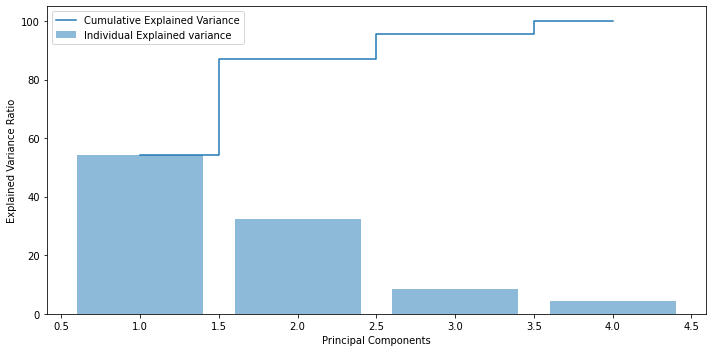

In [12]:
#Plotting
plt.figure(figsize=(10, 5))
plt.bar(range(1, e_vals.size + 1), var_exp, alpha=0.5, align='center', label='Individual Explained variance')
plt.step(range(1, e_vals.size + 1), cum_var_exp, where='mid', label='Cumulative Explained Variance')
plt.ylabel('Explained Variance Ratio')
plt.xlabel('Principal Components')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [20]:
eigen_pairs = [(np.abs(e_vals[i]), e_vecs[:,i]) for i in range(len(e_vals))]
eigen_pairs.sort(reverse=True)
eigen_pairs[:5]

[(2.17821748768195,
  array([-0.24410388, -0.63914113,  0.61378454,  0.3939295 ])),
 (1.3013006373731917,
  array([-0.75674709,  0.0457533 ,  0.15345344, -0.63379217])),
 (0.34425337148288965,
  array([ 0.60295351, -0.11988157,  0.50421613, -0.60649943])),
 (0.179878138498464,
  array([ 0.06476264, -0.75830974, -0.58778114, -0.27438198]))]

In [19]:
w = np.hstack((eigen_pairs[0][1].reshape(4,1),eigen_pairs[1][1].reshape(4,1)))
print('Matrix W: \n', w)
X_sd_pca = X_train_sd.dot(w)

Matrix W: 
 [[-0.24410388 -0.75674709]
 [-0.63914113  0.0457533 ]
 [ 0.61378454  0.15345344]
 [ 0.3939295  -0.63379217]]


In [17]:
X_train_sd.shape, w.shape, X_sd_pca.shape

((1097, 4), (4, 2), (1097, 2))

In [18]:
X_sd_pca

array([[ 0.24352667, -0.66076714],
       [-2.33969928, -0.13044949],
       [-1.25380075,  0.00827162],
       ...,
       [-1.33103962, -0.12962976],
       [-1.52134953,  0.68899534],
       [ 0.57565219,  0.1101247 ]])

In [ ]:
# PCA scikit-learn
from sklearn.decomposition import PCA
pca = PCA().fit(X_std)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlim(0,7,1)
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')

In [ ]:
from sklearn.decomposition import PCA 
sklearn_pca = PCA(n_components=6)
Y_sklearn = sklearn_pca.fit_transform(X_std)

In [ ]:
Y_sklearn.shape